# Homework 5

The code here is a mix of my own work (mainly using other code already written in this class) and that of ChatGPT.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

In [5]:
odd_terms = np.arange(1,10,2)
a = b = c = 1

def sol(x,y,t):
    # Some a and b terms were ommitted because a = b = 1 so they are unimportant and cause
    # unnecessary complexity with parentheses
    total = np.zeros_like(x, dtype=float)
    for m in odd_terms:
        for n in odd_terms:
            coeff = (64*a**2*b**2)/(m**3*n**3*np.pi**6)
            spacial_part = np.sin(m*np.pi*x)*np.sin(n*np.pi*y)
            time_part = np.cos(c*np.pi*t*np.sqrt(m**2+n**2))
            total += coeff*spacial_part*time_part
    return total

(a) The first step is to create a contour plot of the above solution at 5 different values of $t$.

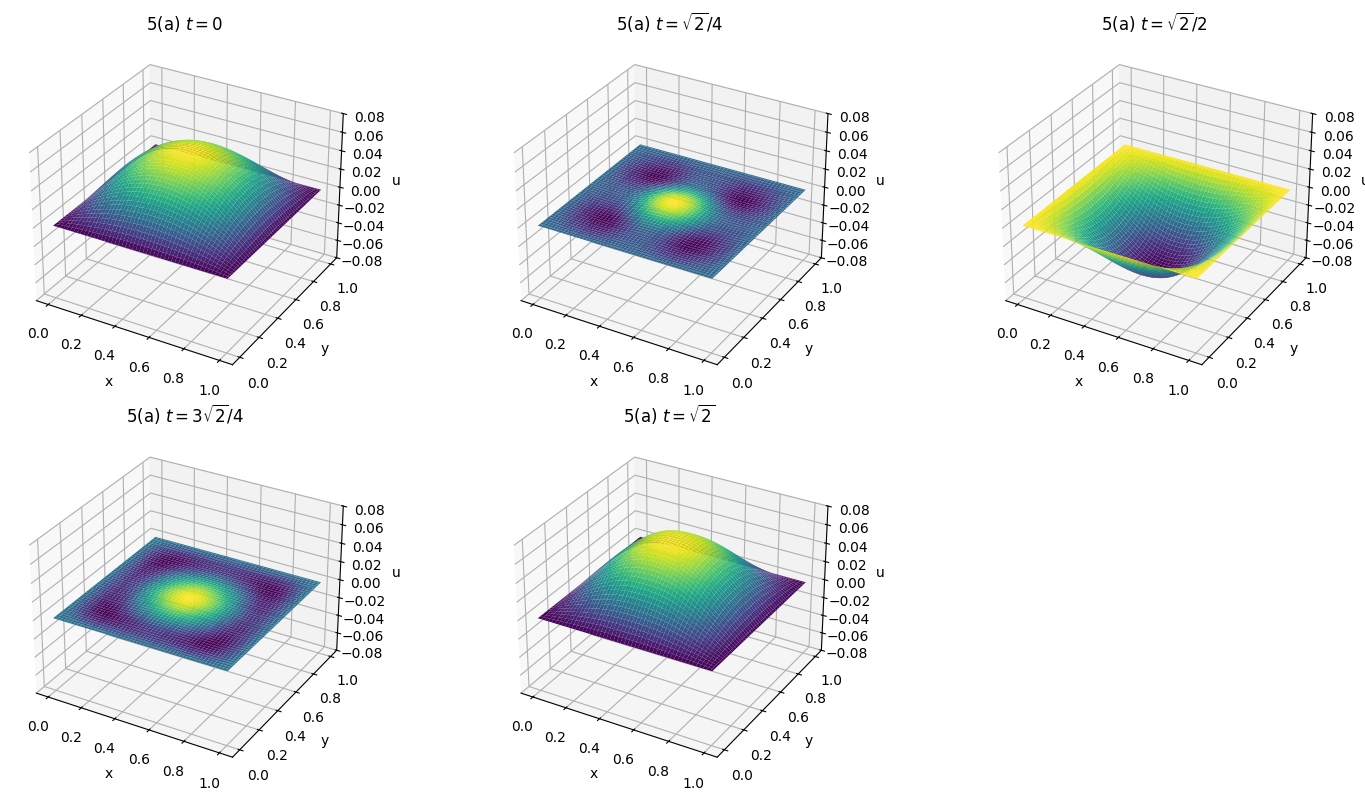

In [10]:
x = np.linspace(0, 1, 100)
y = np.linspace(0, 1, 100)
X, Y = np.meshgrid(x, y)

times = [0, np.sqrt(2)/4, np.sqrt(2)/2,
         3*np.sqrt(2)/4, np.sqrt(2)]

time_labels = [r"5(a) $t=0$", r"5(a) $t=\sqrt{2}/4$", r"5(a) $t=\sqrt{2}/2$", r"5(a) $t=3\sqrt{2}/4$", r"5(a) $t=\sqrt{2}$"]

fig = plt.figure(figsize=(15, 8))

for i, t in enumerate(times):
    ax = fig.add_subplot(2, 3, i + 1, projection="3d")

    U = sol(X, Y, t)

    ax.plot_surface(X, Y, U, cmap="viridis",
                    edgecolor="none")

    ax.set_title(time_labels[i])
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_zlabel("u")

    ax.set_zlim(-0.08, 0.08)

plt.tight_layout()
plt.show()

(b) The next step is to create a plot of displacement at the center of the membrane.

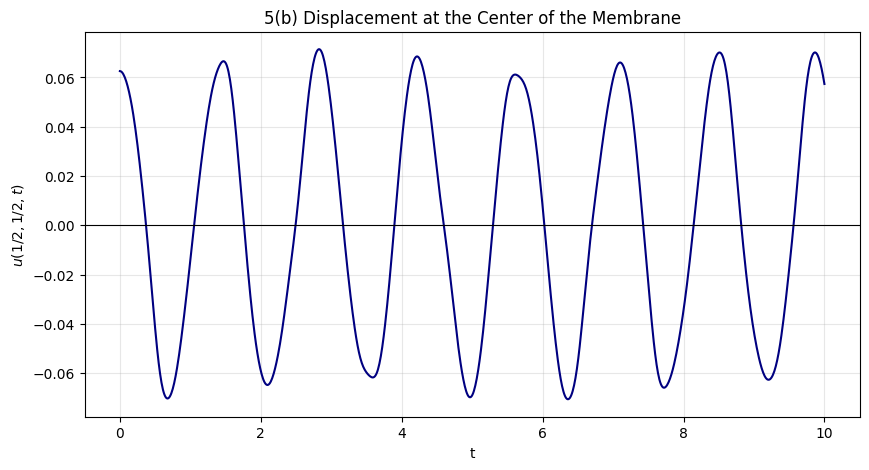

In [8]:
t_values = np.linspace(0, 10, 1000)

u_center = np.zeros_like(t_values)

for m in odd_terms:
    for n in odd_terms:
        coefficient = 64 / (m**3 * n**3 * np.pi**6)

        u_center += (
            coefficient
            * np.sin(m * np.pi / 2)
            * np.sin(n * np.pi / 2)
            * np.cos(np.pi * np.sqrt(m**2 + n**2) * t_values)
        )

plt.figure(figsize=(10, 5))
plt.plot(t_values, u_center, color="navy")
plt.axhline(0, color="black", linewidth=0.8)

plt.xlabel("t")
plt.ylabel(r"$u(1/2,1/2,t)$")
plt.title("5(b) Displacement at the Center of the Membrane")
plt.grid(True, alpha=0.3)
plt.show()